# 02 · Exploring irrigation in the survey

Before modelling: how common is irrigation, where is it, on which crops, and does an irrigated plot look
more productive at first glance? Everything here is an aggregate.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kuhira import style
from kuhira.paths import INTERIM
from kuhira.water_bonus import prepare

style.use()
plots = pd.read_parquet(INTERIM / "plots.parquet")
small = prepare(plots)
f"{len(small):,} small-farmer crop-plots with a harvest, of which {int(small.irrigated.sum()):,} irrigated"

'396,121 small-farmer crop-plots with a harvest, of which 6,820 irrigated'

## 1. Irrigation is rare and flat over time
Fewer than 3% of small-farmer crop-plots are irrigated in any season, with no upward trend. The PSTA5 target
needs ~13,400 more hectares; at FY24/25's pace (1,462 ha) that takes about nine years.

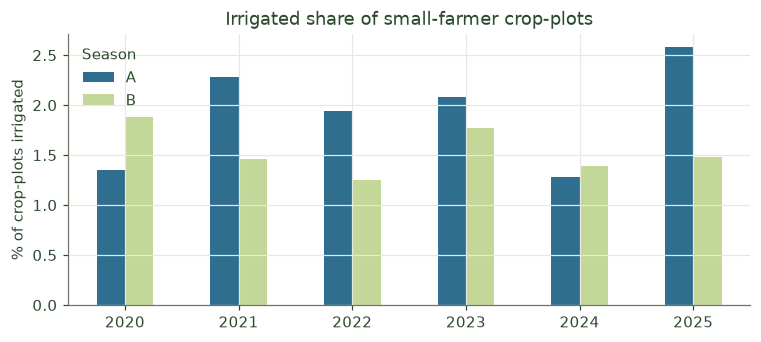

In [2]:
by_season = small.groupby(["year", "season"]).irrigated.mean().unstack()
ax = (by_season * 100).plot(kind="bar", color=[style.WATER, style.PRIMARY], figsize=(8, 3.2))
ax.set(ylabel="% of crop-plots irrigated", xlabel="", title="Irrigated share of small-farmer crop-plots")
ax.legend(title="Season", frameon=False)
plt.xticks(rotation=0);

## 2. Where irrigated plots are
Counts per district are very uneven (from about ten in Rubavu to several hundred in Rwamagana), which is why a
separate water bonus per district cannot be estimated reliably. We estimate one bonus **per crop** and let each
district's crop mix carry it.

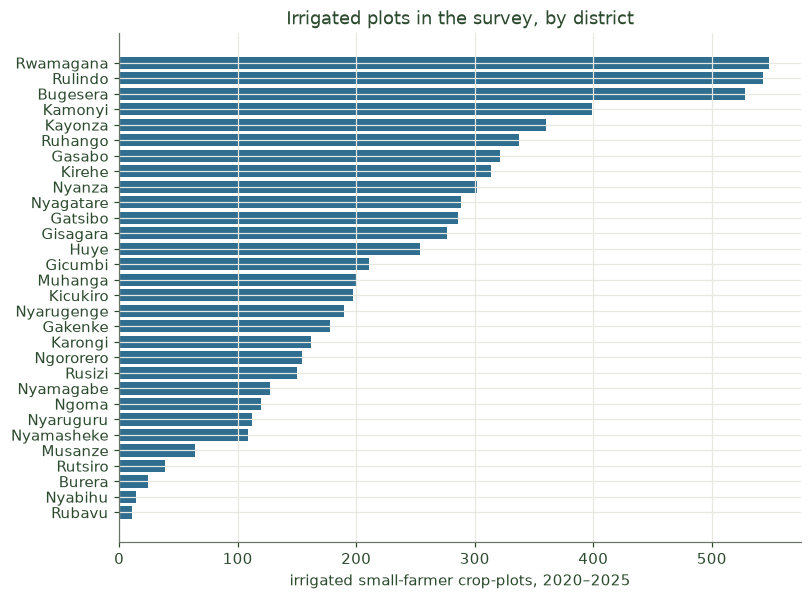

In [3]:
per_district = small.groupby("district").irrigated.agg(["sum", "mean"]).sort_values("sum")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(per_district.index, per_district["sum"], color=style.WATER)
ax.set(xlabel="irrigated small-farmer crop-plots, 2020–2025", title="Irrigated plots in the survey, by district");

## 3. Which crops get water
Vegetables and rice are mostly or often irrigated; maize, beans and sweet potato make up most of the rest.

In [4]:
crops = small.groupby("group").agg(plots=("crop", "size"), irrigated=("irrigated", "sum"))
crops["irrigated_share"] = crops.irrigated / crops.plots
crops.sort_values("irrigated", ascending=False).head(12).style.format(
    {"plots": "{:,.0f}", "irrigated": "{:,.0f}", "irrigated_share": "{:.1%}"})

,plots,irrigated,irrigated_share
group,,,
Vegetables,"6,741","2,082",30.9%
Maize,"63,142","1,029",1.6%
Beans,"95,038",767,0.8%
Paddy rice,578,431,74.6%
Sweet potato,"24,729",392,1.6%
Dessert banana,"31,087",383,1.2%
Cooking banana,"33,302",364,1.1%
Banana for beer,"38,881",328,0.8%
Irish potato,"17,979",215,1.2%


## 4. A first, naive comparison
Median yield on irrigated vs rain-fed plots, no controls. This mixes the effect of water with *who* irrigates
and *where*, so it is only a hint. Notebook 03 does it properly.

In [5]:
main = ["Maize", "Beans", "Irish potato", "Sweet potato", "Vegetables", "Paddy rice"]
naive = (small[small.group.isin(main)].groupby(["group", "irrigated"]).yld.median().unstack()
         .rename(columns={0.0: "rain-fed", 1.0: "irrigated"}))
naive["ratio"] = naive["irrigated"] / naive["rain-fed"]
naive.style.format({"rain-fed": "{:,.0f}", "irrigated": "{:,.0f}", "ratio": "{:.2f}x"})

irrigated,rain-fed,irrigated,ratio
group,,,
Beans,336,261,0.78x
Irish potato,"2,426","1,721",0.71x
Maize,352,548,1.56x
Paddy rice,"2,613","2,885",1.10x
Sweet potato,"3,006","3,588",1.19x
Vegetables,"2,915","3,541",1.21x


## 5. Intercropping is the norm
Most plots carry more than one crop, so per-plot kg/ha understates a sole crop's yield. The model controls for
the number of crops on the plot.

In [6]:
plot_level = small.drop_duplicates(["year", "season", "seg", "farmer", "plot"])
(plot_level.ncrop.value_counts(normalize=True).sort_index() * 100).round(1).rename("% of plots").to_frame()

,% of plots
ncrop,
1.0,32.2
2.0,28.8
3.0,19.7
4.0,10.7
5.0,8.7


## 6. Inputs travel together
Irrigating farmers use more fertilizer and improved seed. If we ignored that, the water bonus would absorb the
fertilizer's effect too, so both go into the model.

In [7]:
small.groupby("irrigated")[["fert_used", "iseed"]].mean().rename(index={0.0: "rain-fed", 1.0: "irrigated"}).style.format("{:.1%}")

,fert_used,iseed
irrigated,,
rain-fed,31.2%,11.8%
irrigated,73.6%,28.6%
